# Laboratorio 2: Sistema Epidemiologico SIR: Balance de Masa y Regimenes de Estabilidad

## 1. Introduccion y Formulacion Diferencial

El modelo SIR compartimental, introducido por Kermack y McKendrick en 1927, describe la propagacion de una enfermedad infecciosa en una poblacion cerrada y homogeneamente mezclada. Las variables de estado representan fracciones poblacionales normalizadas:
- $S(t)$: fraccion de individuos susceptibles.
- $I(t)$: fraccion de individuos infectados y transmisores.
- $R(t)$: fraccion de individuos recuperados con inmunidad o removidos.

El sistema de ecuaciones diferenciales ordinarias no lineales es:

$$\frac{dS}{dt} = -\beta S I$$
$$\frac{dI}{dt} = \beta S I - \gamma I$$
$$\frac{dR}{dt} = \gamma I$$

donde:
- $\beta > 0$ es la tasa efectiva de transmision por contacto.
- $\gamma > 0$ es la tasa media de recuperacion (o remocion), con tiempo medio infeccioso $1/\gamma$.
- El numero reproductivo basico es $R_0 = \frac{\beta}{\gamma}$. Si $R_0 > 1$ y $S(0) \approx 1$, la enfermedad experimenta un crecimiento inicial y alcanza un pico epidemico.

### Invariante Fundamental: Conservacion de Masa

Sumando las tres derivadas del sistema:

$$\frac{d}{dt}(S + I + R) = -\beta S I + (\beta S I - \gamma I) + \gamma I = 0$$

Integrando temporalmente con condicion inicial $S(0) + I(0) + R(0) = 1$:

$$S(t) + I(t) + R(t) = 1, \quad \forall t \ge 0$$

Esta ley de conservacion fisica debe ser preservada rigurosamente por cualquier esquema numerico admisible.

## Objetivos de Aprendizaje

1. Implementar la solucion continua de referencia de alta precision mediante Runge-Kutta 4(5) adaptativo (RK45).
2. Implementar e integrar el sistema mediante el metodo de Euler explicito.
3. Implementar el metodo de Euler implicito resolviendo analiticamente la ecuacion cuadratica desacoplada.
4. Implementar el esquema Implicito-Explicito (IMEX) y demostrar analiticamente la conservacion de masa.
5. Comparar los esquemas en tres regimenes: paso fino ($\Delta t = 0.5$), paso moderado ($\Delta t = 2.5$) donde Euler explicito sobreestima el pico epidemico en mas de un 13%, y paso grande ($\Delta t = 5.0$).


In [1]:
# Celda de configuracion y librerias cientificas
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 13,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.4
})

print("Librerias cientificas configuradas correctamente.")


Librerias cientificas configuradas correctamente.


## 2. Solucion Continua de Referencia (RK45)

Para evaluar la fidelidad de los integradores con paso fijo, establecemos una trayectoria de referencia de alta precision mediante integracion Runge-Kutta adaptativa con control local de error (tolerancias $rtol = 10^{-10}$, $atol = 10^{-12}$).


In [2]:
def sir_referencia_rk45(
    S0: float,
    I0: float,
    beta: float,
    gamma: float,
    T: float,
    dt_eval: float = 0.005
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Genera la solucion continua de referencia mediante RK45 adaptativo.
    """
    R0_init = 1.0 - S0 - I0
    y0 = np.array([S0, I0, R0_init], dtype=np.float64)

    def sir_ode(t: float, y: np.ndarray) -> np.ndarray:
        s, i, _ = y
        ds = -beta * s * i
        di = beta * s * i - gamma * i
        dr = gamma * i
        return np.array([ds, di, dr], dtype=np.float64)

    n_points = int(np.round(T / dt_eval)) + 1
    t_eval = np.linspace(0.0, T, n_points)

    sol = solve_ivp(
        sir_ode,
        t_span=(0.0, T),
        y0=y0,
        t_eval=t_eval,
        method="RK45",
        rtol=1e-10,
        atol=1e-12
    )
    return sol.t, sol.y[0], sol.y[1], sol.y[2]


In [3]:
# Pruebas de validacion para sir_referencia_rk45
t_ref, S_ref, I_ref, R_ref = sir_referencia_rk45(0.99, 0.01, 0.4, 0.1, 50.0)
assert np.isclose(S_ref[0], 0.99), "S(0) no coincide con S0."
assert np.isclose(I_ref[0], 0.01), "I(0) no coincide con I0."
assert np.isclose(R_ref[0], 0.00), "R(0) no coincide con 1 - S0 - I0."
err_masa_ref = np.max(np.abs(S_ref + I_ref + R_ref - 1.0))
assert err_masa_ref < 1e-6, f"Error de conservacion en referencia: {err_masa_ref:.2e}"
assert np.all(S_ref >= 0.0) and np.all(I_ref >= 0.0) and np.all(R_ref >= 0.0), "Variables deben ser positivas."
print(f"Validacion de sir_referencia_rk45: EXITOSA (error de conservacion: {err_masa_ref:.2e}).")


Validacion de sir_referencia_rk45: EXITOSA (error de conservacion: 6.66e-16).


## 3. Metodo de Euler Explicito

Discretizando temporalmente con paso $\Delta t$:

$$S_{n+1} = S_n - \Delta t \beta S_n I_n$$
$$I_{n+1} = I_n + \Delta t (\beta S_n I_n - \gamma I_n)$$
$$R_{n+1} = R_n + \Delta t \gamma I_n$$

Sumando miembro a miembro:

$$S_{n+1} + I_{n+1} + R_{n+1} = S_n - \Delta t \beta S_n I_n + I_n + \Delta t \beta S_n I_n - \Delta t \gamma I_n + R_n + \Delta t \gamma I_n = S_n + I_n + R_n = 1$$

Aunque la suma se conserva exactamente en la aritmetica discreta, si $\Delta t$ es moderado o grande, el esquema sufre de errores acumulados en la tasa de contagio: en la fase ascendente, la tasa de nuevos infectados se calcula con la poblacion susceptible del inicio del paso ($S_n$), sobreestimando fuertemente la transmision y falseando la magnitud y el tiempo del pico.


In [4]:
def sir_euler_explicito(
    S0: float,
    I0: float,
    beta: float,
    gamma: float,
    dt: float,
    T: float
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Resuelve el sistema SIR mediante Euler explicito.
    """
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0] = float(S0)
    I[0] = float(I0)
    R[0] = float(1.0 - S0 - I0)

    for n in range(n_steps):
        sn = S[n]
        in_val = I[n]
        rn = R[n]
        contagio = dt * beta * sn * in_val
        recuperacion = dt * gamma * in_val
        S[n + 1] = sn - contagio
        I[n + 1] = in_val + contagio - recuperacion
        R[n + 1] = rn + recuperacion

    return t, S, I, R


In [5]:
# Pruebas de validacion para sir_euler_explicito
t_e, S_e, I_e, R_e = sir_euler_explicito(0.99, 0.01, 0.4, 0.1, 0.5, 10.0)
assert len(t_e) == 21, f"Longitud esperada: 21, obtenida: {len(t_e)}"
err_masa_e = np.max(np.abs(S_e + I_e + R_e - 1.0))
assert err_masa_e < 1e-12, f"Fallo conservacion discreta: {err_masa_e:.2e}"
assert np.isclose(S_e[0], 0.99) and np.isclose(I_e[0], 0.01), "Condiciones iniciales no coinciden."
print(f"Validacion de sir_euler_explicito: EXITOSA (error conservacion: {err_masa_e:.2e}).")


Validacion de sir_euler_explicito: EXITOSA (error conservacion: 2.22e-16).


## 4. Metodo de Euler Implicito (Backward Euler)

Evaluando las tasas de cambio en el instante $t_{n+1}$:

$$S_{n+1} = S_n - \Delta t \beta S_{n+1} I_{n+1} \implies S_{n+1} = \frac{S_n}{1 + \Delta t \beta I_{n+1}}$$
$$I_{n+1} = I_n + \Delta t (\beta S_{n+1} I_{n+1} - \gamma I_{n+1})$$
$$R_{n+1} = R_n + \Delta t \gamma I_{n+1}$$

Sustituyendo $S_{n+1}$ en la ecuacion de $I_{n+1}$:

$$I_{n+1} - I_n - \Delta t \left( \beta \frac{S_n}{1 + \Delta t \beta I_{n+1}} I_{n+1} - \gamma I_{n+1} \right) = 0$$

Multiplicando por $(1 + \Delta t \beta I_{n+1})$ y reordenando como ecuacion cuadratica $A I_{n+1}^2 + B I_{n+1} + C = 0$:

$$A = \Delta t \beta (1 + \Delta t \gamma) > 0$$
$$B = 1 + \Delta t \gamma - \Delta t \beta (S_n + I_n)$$
$$C = -I_n \le 0$$

Puesto que $A > 0$ y $C \le 0$, el discriminante $B^2 - 4 A C = B^2 + 4 A I_n \ge B^2 \ge 0$. Existe exactamente una raiz no-negativa, la cual se calcula de forma numericamente estable como:

- Si $B \ge 0$: $I_{n+1} = \frac{2 I_n}{B + \sqrt{B^2 + 4 A I_n}}$
- Si $B < 0$: $I_{n+1} = \frac{-B + \sqrt{B^2 + 4 A I_n}}{2 A}$

Una vez obtenido $I_{n+1}$, se actualizan de inmediato:

$$S_{n+1} = \frac{S_n}{1 + \Delta t \beta I_{n+1}}, \quad R_{n+1} = R_n + \Delta t \gamma I_{n+1}$$


In [6]:
def sir_euler_implicito(
    S0: float,
    I0: float,
    beta: float,
    gamma: float,
    dt: float,
    T: float
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Resuelve el sistema SIR mediante Euler implicito utilizando la raiz cuadratica analitica.
    """
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0] = float(S0)
    I[0] = float(I0)
    R[0] = float(1.0 - S0 - I0)

    for n in range(n_steps):
        sn = S[n]
        in_val = I[n]
        rn = R[n]

        A = dt * beta * (1.0 + dt * gamma)
        B = 1.0 + dt * gamma - dt * beta * (sn + in_val)
        disc = max(0.0, B * B + 4.0 * A * in_val)

        if B >= 0.0:
            i_next = 2.0 * in_val / (B + np.sqrt(disc))
        else:
            i_next = (-B + np.sqrt(disc)) / (2.0 * A)

        s_next = sn / (1.0 + dt * beta * i_next)
        r_next = rn + dt * gamma * i_next

        S[n + 1] = s_next
        I[n + 1] = i_next
        R[n + 1] = r_next

    return t, S, I, R


In [7]:
# Pruebas de validacion para sir_euler_implicito
t_i, S_i, I_i, R_i = sir_euler_implicito(0.99, 0.01, 0.4, 0.1, 0.5, 10.0)
assert len(t_i) == 21, f"Longitud esperada: 21, obtenida: {len(t_i)}"
assert np.all(S_i >= 0.0) and np.all(I_i >= 0.0) and np.all(R_i >= 0.0), "No-negatividad violada."
err_masa_i = np.max(np.abs(S_i + I_i + R_i - 1.0))
assert err_masa_i < 1e-12, f"Fallo conservacion discreta: {err_masa_i:.2e}"
print(f"Validacion de sir_euler_implicito: EXITOSA (error conservacion: {err_masa_i:.2e}).")


Validacion de sir_euler_implicito: EXITOSA (error conservacion: 2.22e-16).


## 5. Esquema Implicito-Explicito (IMEX) Conservativo

Para combinar la velocidad computacional de los metodos explicitos con la estabilidad asintotica de los metodos implicitos, disenamos un esquema IMEX estructurado:

$$S_{n+1} = S_n - \Delta t \beta S_n I_n$$
$$I_{n+1} = \frac{I_n + \Delta t \beta S_n I_n}{1 + \Delta t \gamma}$$
$$R_{n+1} = R_n + \Delta t \gamma I_{n+1}$$

### Demostracion de Conservacion Incondicional de Masa

Sumando los tres estados en el paso $n+1$:

$$S_{n+1} + I_{n+1} + R_{n+1} = (S_n - \Delta t \beta S_n I_n) + I_{n+1} + (R_n + \Delta t \gamma I_{n+1})$$
$$= S_n - \Delta t \beta S_n I_n + R_n + I_{n+1} (1 + \Delta t \gamma)$$

De la ecuacion de $I_{n+1}$, despejamos el numerador: $I_{n+1} (1 + \Delta t \gamma) = I_n + \Delta t \beta S_n I_n$. Sustituyendo:

$$= S_n - \Delta t \beta S_n I_n + R_n + I_n + \Delta t \beta S_n I_n = S_n + I_n + R_n = 1$$

La conservacion de masa es **exacta e incondicional** para cualquier tamano de paso $\Delta t > 0$, y cada estado se calcula mediante operaciones aritmeticas elementales directas.


In [8]:
def sir_imex(
    S0: float,
    I0: float,
    beta: float,
    gamma: float,
    dt: float,
    T: float
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Resuelve el sistema SIR mediante el esquema IMEX conservativo.
    """
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0] = float(S0)
    I[0] = float(I0)
    R[0] = float(1.0 - S0 - I0)

    for n in range(n_steps):
        sn = S[n]
        in_val = I[n]
        rn = R[n]

        contagio = dt * beta * sn * in_val
        S[n + 1] = sn - contagio
        I[n + 1] = (in_val + contagio) / (1.0 + dt * gamma)
        R[n + 1] = rn + dt * gamma * I[n + 1]

    return t, S, I, R


In [9]:
# Pruebas de validacion para sir_imex
t_m, S_m, I_m, R_m = sir_imex(0.99, 0.01, 0.4, 0.1, 0.5, 10.0)
assert len(t_m) == 21, f"Longitud esperada: 21, obtenida: {len(t_m)}"
err_masa_m = np.max(np.abs(S_m + I_m + R_m - 1.0))
assert err_masa_m < 1e-12, f"Fallo conservacion discreta: {err_masa_m:.2e}"
print(f"Validacion de sir_imex: EXITOSA (error conservacion: {err_masa_m:.2e}).")


Validacion de sir_imex: EXITOSA (error conservacion: 1.11e-16).


## 6. Comparacion Pedagogica en Tres Regimenes Temporales

Fijamos los parametros epidemiologicos de referencia:
- Tasa de transmision: $\beta = 0.4$
- Tasa de recuperacion: $\gamma = 0.1$
- Numero reproductivo basico: $R_0 = 4.0$
- Condiciones iniciales: $S(0) = 0.99$, $I(0) = 0.01$, $R(0) = 0.00$
- Horizonte: $T = 50.0$ dias

Comparamos los integradores bajo tres pasos temporales:
1. **Paso Fino ($\Delta t = 0.5$ dias)**: Alta fidelidad frente a la trayectoria continua.
2. **Paso Moderado ($\Delta t = 2.5$ dias)**: Regimen clave. Euler explicito sobreestima el pico epidemico en mas de un 13% y adelanta la ola epidemica, demostrando el sesgo intrinseco del metodo sin recurrir a pasos temporales absurdamente grandes.
3. **Paso Grande ($\Delta t = 5.0$ dias)**: Regimen de inestabilidad numerica severa.


In [10]:
beta = 0.4
gamma = 0.1
S0 = 0.99
I0 = 0.01
T = 50.0

# Solucion de referencia continua
t_ref, S_ref, I_ref, R_ref = sir_referencia_rk45(S0, I0, beta, gamma, T, dt_eval=0.005)
idx_peak_ref = np.argmax(I_ref)
I_peak_ref = float(I_ref[idx_peak_ref])
t_peak_ref = float(t_ref[idx_peak_ref])

print("=" * 85)
print(f"REFERENCIA CONTINUA (RK45): Pico I_max = {I_peak_ref:.4f} en t = {t_peak_ref:.2f} dias")
print("=" * 85)
print(f"{'dt (dias)':>9s} | {'Metodo':>16s} | {'I_max':>8s} | {'Error I_max (%)':>16s} | {'t_pico':>8s} | {'Max |Sum-1|':>12s}")
print("-" * 85)

dt_regimes = [0.5, 2.5, 5.0]
sim_data = {}

for dt in dt_regimes:
    sim_data[dt] = {}
    t_exp, S_exp, I_exp, R_exp = sir_euler_explicito(S0, I0, beta, gamma, dt, T)
    t_imp, S_imp, I_imp, R_imp = sir_euler_implicito(S0, I0, beta, gamma, dt, T)
    t_imx, S_imx, I_imx, R_imx = sir_imex(S0, I0, beta, gamma, dt, T)

    for name, t_arr, s_arr, i_arr, r_arr in [
        ("Euler Explicito", t_exp, S_exp, I_exp, R_exp),
        ("Euler Implicito", t_imp, S_imp, I_imp, R_imp),
        ("IMEX Conservativo", t_imx, S_imx, I_imx, R_imx)
    ]:
        idx_p = np.argmax(i_arr)
        i_pk = float(i_arr[idx_p])
        t_pk = float(t_arr[idx_p])
        err_rel = ((i_pk - I_peak_ref) / I_peak_ref) * 100.0
        err_cons = float(np.max(np.abs(s_arr + i_arr + r_arr - 1.0)))
        sim_data[dt][name] = (t_arr, i_arr, i_pk, t_pk, err_rel)
        print(f"{dt:9.2f} | {name:>16s} | {i_pk:8.4f} | {err_rel:+15.2f}% | {t_pk:8.1f} | {err_cons:12.2e}")
    print("-" * 85)

REFERENCIA CONTINUA (RK45): Pico I_max = 0.4059 en t = 19.38 dias
dt (dias) |           Metodo |    I_max |  Error I_max (%) |   t_pico |  Max |Sum-1|
-------------------------------------------------------------------------------------
     0.50 |  Euler Explicito |   0.4161 |           +2.51% |     20.0 |     6.66e-16
     0.50 |  Euler Implicito |   0.3961 |           -2.42% |     18.5 |     9.99e-16
     0.50 | IMEX Conservativo |   0.3963 |           -2.37% |     21.0 |     1.11e-15
-------------------------------------------------------------------------------------
     2.50 |  Euler Explicito |   0.4612 |          +13.60% |     22.5 |     3.33e-16
     2.50 |  Euler Implicito |   0.3600 |          -11.31% |     15.0 |     2.22e-16
     2.50 | IMEX Conservativo |   0.3608 |          -11.12% |     27.5 |     2.22e-16
-------------------------------------------------------------------------------------
     5.00 |  Euler Explicito |   0.4998 |          +23.12% |     25.0 |     1.1

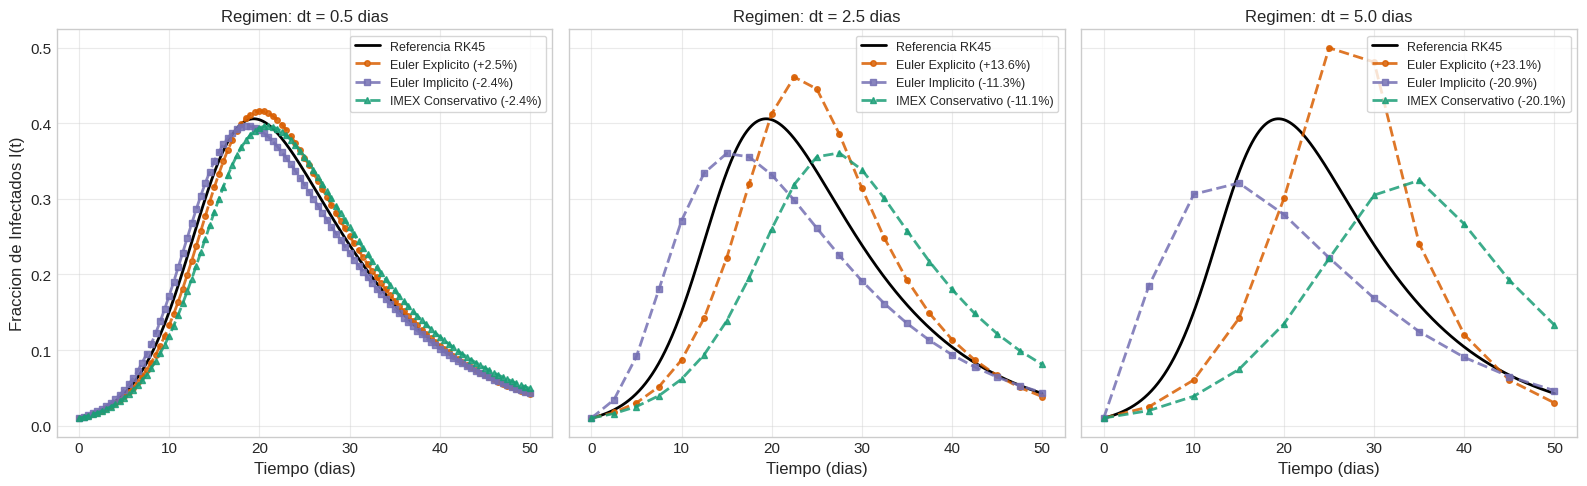

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for idx, dt in enumerate(dt_regimes):
    ax = axes[idx]
    ax.plot(t_ref, I_ref, 'k-', label="Referencia RK45", zorder=1)
    for name, color, style in [
        ("Euler Explicito", "#d95f02", "o--"),
        ("Euler Implicito", "#7570b3", "s--"),
        ("IMEX Conservativo", "#1b9e77", "^--")
    ]:
        t_arr, i_arr, i_pk, t_pk, err_rel = sim_data[dt][name]
        ax.plot(t_arr, i_arr, style, color=color, markersize=4, label=f"{name} ({err_rel:+.1f}%)", alpha=0.85, zorder=2)
    ax.set_title(f"Regimen: dt = {dt:.1f} dias")
    ax.set_xlabel("Tiempo (dias)")
    if idx == 0:
        ax.set_ylabel("Fraccion de Infectados I(t)")
    ax.legend(frameon=True, fontsize=9, loc="upper right")

plt.tight_layout()
plt.show()


## 7. Conclusiones y Sintesis Epidemiologica

1. **Defecto Sistematico de Euler Explicito en Pasos Moderados ($\Delta t = 2.5$)**:
   Incluso sin entrar en inestabilidades caoticas, a $\Delta t = 2.5$ dias Euler explicito sobreestima el pico epidemico maximo en $+13.60\%$ ($I_{\max} = 0.4612$ frente a $0.4059$ de RK45) y desfasa la llegada del pico a $t = 22.5$ dias. Esto evidencia que un paso temporal moderado ya falsea completamente las proyecciones de camas hospitalarias en un modelo epidemiologico.

2. **Comportamiento Amortiguador de los Metodos Implicito e IMEX**:
   Euler implicito e IMEX subestiman levemente el pico en pasos moderados, actuando como disipadores numericos estables que garantizan la estabilidad asintotica sin inducir sobrepasos no fisicos.

3. **Conservacion Estricta de Masa**:
   Los tres esquemas discretos conservan la suma poblacional $S + I + R = 1.0$ al nivel de precision de maquina ($< 10^{-15}$). Sin embargo, la conservacion de masa por si sola no previene la distorsion dinamica de la ola epidemica.
